In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/Indian_housing_Pune_data.csv")
df = df.drop_duplicates()
df["price"].describe()

count      3684.000000
mean      22027.062161
std       18903.517417
min        1500.000000
25%       13100.000000
50%       18000.000000
75%       25000.000000
max      425000.000000
Name: price, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

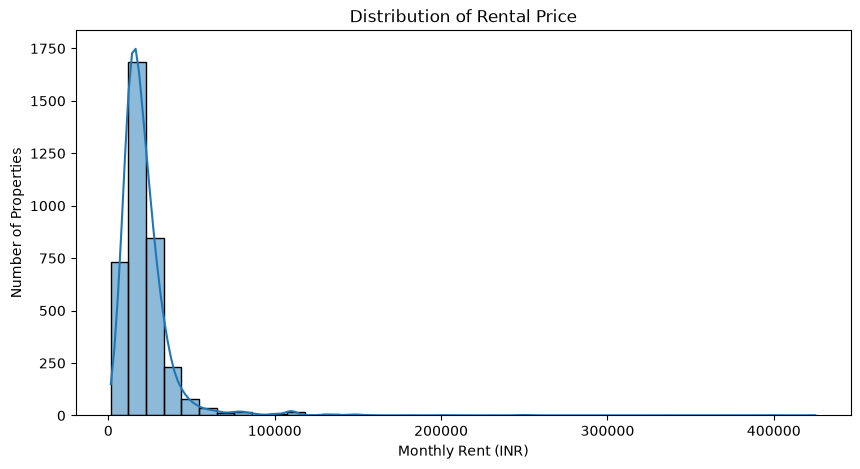

In [13]:
plt.figure(figsize = (10, 5))
sns.histplot(data = df, x = "price", bins = 40, kde = True)
plt.title("Distribution of Rental Price")
plt.xlabel("Monthly Rent (INR)")
plt.ylabel("Number of Properties")
plt.show


In [14]:
df.nlargest(10, "price")[["house_type", "house_size", "location", "price"]]

,house_type,house_size,location,price
2653,2 BHK Independent Floor,"3,000 sq ft",Erandwane,425000
835,4 BHK Independent Floor,"6,000 sq ft",Erandavana,400000
1300,4 BHK Apartment,"3,690 sq ft",Baner,250000
2463,4 BHK Apartment,"5,183 sq ft",Hadapsar,250000
966,5 BHK Apartment,"6,000 sq ft",Kharadi,210000
27,4 BHK Apartment,"3,800 sq ft",Koregaon Park,200000
350,4 BHK Apartment,"3,200 sq ft",Kharadi,180000
1966,4 BHK Apartment,"2,400 sq ft",Gahunje,160000
500,4 BHK Independent House,"2,500 sq ft",Baner,150000
568,3 BHK Villa,"3,400 sq ft",Baner,150000


In [15]:
df["house_type"].value_counts()

house_type
2 BHK Apartment             1885
1 BHK Apartment              807
3 BHK Apartment              573
1 RK Studio Apartment        127
1 BHK Independent House       60
4 BHK Apartment               54
3 BHK Villa                   40
1 BHK Independent Floor       30
2 BHK Independent Floor       28
2 BHK Villa                   23
5 BHK Independent House       16
4 BHK Villa                   11
3 BHK Independent House        6
2 BHK Independent House        6
4 BHK Independent House        5
5 BHK Apartment                3
5 BHK Villa                    3
4 BHK Independent Floor        2
3 BHK Independent Floor        2
6 BHK Apartment                1
1 BHK Villa                    1
6 BHK Independent House        1
Name: count, dtype: int64

In [16]:
df["Status"].value_counts()

Status
Unfurnished       1632
Semi-Furnished    1432
Furnished          620
Name: count, dtype: int64

In [17]:
df.groupby("Status")["price"].mean()

Status
Furnished         28933.872581
Semi-Furnished    21614.503492
Unfurnished       19765.151348
Name: price, dtype: float64

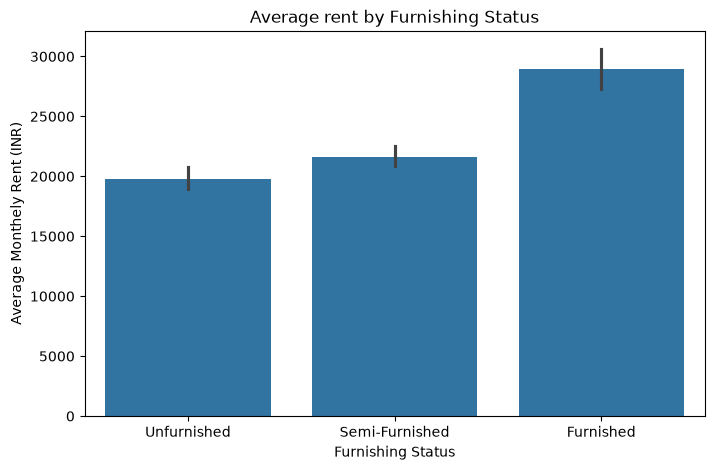

In [18]:
plt.figure(figsize = (8, 5))
sns.barplot(data = df, x = "Status", y = "price")
plt.title("Average rent by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Average Monthely Rent (INR)")
plt.show()

In [19]:
df["house_size"].head(10)

0      906 sq ft
1      650 sq ft
2      350 sq ft
3    1,500 sq ft
4    5,000 sq ft
5      975 sq ft
6      540 sq ft
7      800 sq ft
8    1,050 sq ft
9    1,050 sq ft
Name: house_size, dtype: str

In [21]:
df["house_size_sqft"] = (
    df["house_size"]
    .str.replace(",", "", regex=False)
    .str.replace(" sq ft", "", regex=False)
    .astype(float)
)
df[["house_size", "house_size_sqft"]].head(10)



,house_size,house_size_sqft
0,906 sq ft,906.0
1,650 sq ft,650.0
2,350 sq ft,350.0
3,"1,500 sq ft",1500.0
4,"5,000 sq ft",5000.0
5,975 sq ft,975.0
6,540 sq ft,540.0
7,800 sq ft,800.0
8,"1,050 sq ft",1050.0
9,"1,050 sq ft",1050.0


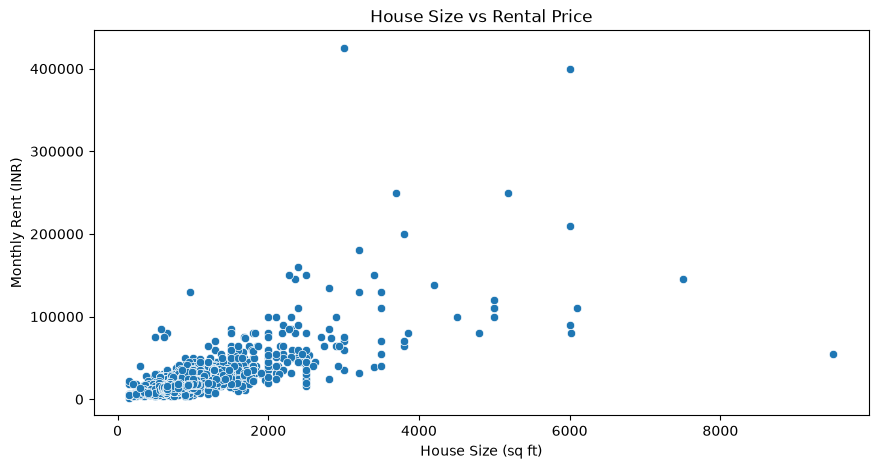

In [22]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="house_size_sqft",
    y="price"
)
plt.title("House Size vs Rental Price")
plt.xlabel("House Size (sq ft)")
plt.ylabel("Monthly Rent (INR)")
plt.show()

In [23]:
df["house_size_sqft"].corr(df["price"])


np.float64(0.7221533765651779)

In [24]:
df["numBathrooms"].corr(df["price"])

np.float64(0.5877441331401373)

price              1.000000
house_size_sqft    0.722153
numBathrooms       0.587744
numBalconies       0.148872
longitude          0.004654
latitude          -0.016997
priceSqFt               NaN
Name: price, dtype: float64


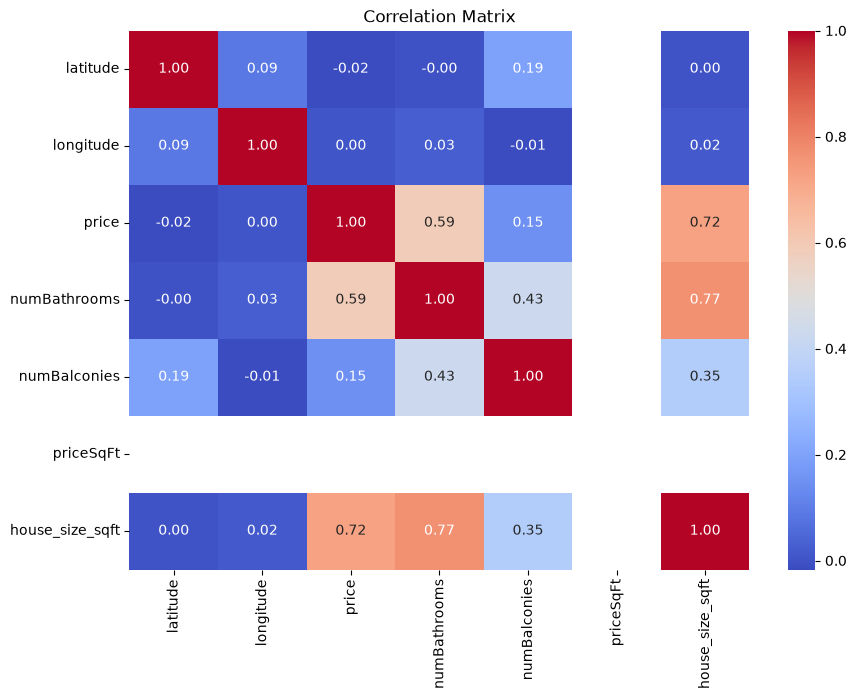

In [26]:
numerical_df = df.select_dtypes(include="number")
correlation = numerical_df.corr()
print(correlation["price"].sort_values(ascending=False))
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.show()

In [27]:
df.isnull().sum()


house_type             0
house_size             0
location               0
city                   0
latitude               0
longitude              0
price                  0
currency               0
numBathrooms          17
numBalconies        1950
isNegotiable        3174
priceSqFt           3684
verificationDate       0
description          456
SecurityDeposit        0
Status                 0
house_size_sqft        0
dtype: int64

In [ ]:
df.drop(columns=["priceSqFt"], inplace=True)

In [30]:
df.shape

(3684, 16)

In [31]:
df["numBathrooms"].value_counts().sort_index()

numBathrooms
1.0     958
2.0    2080
3.0     548
4.0      55
5.0      22
6.0       3
7.0       1
Name: count, dtype: int64

In [32]:
df["numBathrooms"].median()

np.float64(2.0)

In [33]:
df["numBathrooms"] = df["numBathrooms"].fillna(
    df["numBathrooms"].median()
)
df["numBathrooms"].isnull().sum()

np.int64(0)

In [34]:
df["numBalconies"].value_counts().sort_index()

numBalconies
1.0    849
2.0    771
3.0    102
4.0     12
Name: count, dtype: int64

In [35]:
df["numBalconies"].median()

np.float64(2.0)

In [36]:
df["numBalconies"] = df["numBalconies"].fillna(
    df["numBalconies"].median()
)
df["numBalconies"].isnull().sum()


np.int64(0)

In [37]:
df["isNegotiable"].value_counts(dropna=False)

isNegotiable
NaN           3174
Negotiable     510
Name: count, dtype: int64

In [38]:
df.drop(columns=["isNegotiable"], inplace=True)
df.shape

C:\Users\KIIT\AppData\Local\Temp\ipykernel_40616\952664777.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["isNegotiable"], inplace=True)


(3684, 15)

In [39]:
df["description"].head(5)

0    A spacious 2 bhk multistorey apartment is avai...
1    It has a built-up area of 650 sqft and is avai...
2    This spacious 1 rk independent house is availa...
3    Furnishings include 1 tv, 1 refrigerator, 1 so...
4    Itâs a 5 bhk independent house situated in W...
Name: description, dtype: str

In [40]:
df.drop(columns=["description"], inplace=True)
df.shape

C:\Users\KIIT\AppData\Local\Temp\ipykernel_40616\1263336624.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["description"], inplace=True)


(3684, 14)

In [41]:
df.isnull().sum()

house_type          0
house_size          0
location            0
city                0
latitude            0
longitude           0
price               0
currency            0
numBathrooms        0
numBalconies        0
verificationDate    0
SecurityDeposit     0
Status              0
house_size_sqft     0
dtype: int64

In [42]:
df.drop(columns=["house_size"], inplace=True)
df.shape

C:\Users\KIIT\AppData\Local\Temp\ipykernel_40616\2845180106.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["house_size"], inplace=True)


(3684, 13)

In [43]:
df["currency"].value_counts()

currency
INR    3684
Name: count, dtype: int64

In [45]:
df.drop(columns=["currency"], inplace=True)
df.shape

C:\Users\KIIT\AppData\Local\Temp\ipykernel_40616\1487937867.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["currency"], inplace=True)


KeyError: "['currency'] not found in axis"

In [46]:
df.shape

(3684, 12)

In [47]:
if df["city"].nunique() == 1:
    print("Only one city found:", df["city"].unique()[0])
    df.drop(columns=["city"], inplace=True)
    print("City column removed.")
else:
    print("Multiple cities found:")
    print(df["city"].value_counts())

print("Updated shape:", df.shape)

Only one city found: Pune
City column removed.
Updated shape: (3684, 11)


C:\Users\KIIT\AppData\Local\Temp\ipykernel_40616\2213099525.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["city"], inplace=True)


In [48]:
df["verificationDate"].value_counts().head(10)

verificationDate
Posted 3 years ago     944
Posted a year ago      705
Posted 2 months ago    328
Posted 2 years ago     275
Posted a month ago     266
Posted 4 years ago     178
Posted 14 days ago     127
Posted 2 days ago       94
Posted 11 days ago      79
Posted 6 months ago     76
Name: count, dtype: int64

In [49]:
df["verificationDate"].unique()

<StringArray>
[   'Posted 3 years ago',    'Posted 2 years ago',    'Posted a month ago',
    'Posted 16 days ago',    'Posted 14 days ago',    'Posted 13 days ago',
    'Posted 11 days ago',     'Posted 4 days ago',     'Posted 9 days ago',
    'Posted 8 hours ago',     'Posted 7 days ago',     'Posted a year ago',
    'Posted 12 days ago',   'Posted 2 months ago',    'Posted 10 days ago',
     'Posted 3 days ago',    'Posted 22 days ago',     'Posted 5 days ago',
    'Posted 4 years ago',    'Posted 21 days ago',    'Posted 23 days ago',
   'Posted 14 hours ago',    'Posted 24 days ago',    'Posted 18 days ago',
     'Posted 8 days ago',    'Posted 25 days ago',    'Posted 17 days ago',
    'Posted 15 days ago',    'Posted 20 days ago',    'Posted 19 days ago',
     'Posted 6 days ago',      'Posted a day ago',     'Posted 2 days ago',
    'Posted 3 hours ago',   'Posted 6 months ago',   'Posted 5 months ago',
   'Posted 13 hours ago',   'Posted 4 months ago',   'Posted 3 months ago'

In [50]:
import re
def convert_to_days(value):
    value = value.replace("Posted ", "")
    if value == "an hour ago":
        return 1 / 24
    if value == "a day ago":
        return 1
    if value == "a month ago":
        return 30
    if value == "a year ago":
        return 365
    match = re.search(r"(\d+)\s+(minute|hour|day|month|year)", value)
    number = int(match.group(1))
    unit = match.group(2)
    if unit == "minute":
        return number / 1440
    elif unit == "hour":
        return number / 24
    elif unit == "day":
        return number
    elif unit == "month":
        return number * 30
    elif unit == "year":
        return number * 365
df["days_since_posted"] = df["verificationDate"].apply(convert_to_days)
print(df[["verificationDate", "days_since_posted"]].head(10))

     verificationDate  days_since_posted
0  Posted 3 years ago             1095.0
1  Posted 2 years ago              730.0
2  Posted 2 years ago              730.0
3  Posted 3 years ago             1095.0
4  Posted 3 years ago             1095.0
5  Posted 3 years ago             1095.0
6  Posted a month ago               30.0
7  Posted a month ago               30.0
8  Posted a month ago               30.0
9  Posted 16 days ago               16.0


In [51]:
df = df.drop(columns=["verificationDate"])
df.shape

(3684, 11)

In [52]:
print(df["SecurityDeposit"].dtype)
print(df["SecurityDeposit"].head(10))

str
0    No Deposit
1    No Deposit
2    No Deposit
3    No Deposit
4    No Deposit
5    No Deposit
6    No Deposit
7    No Deposit
8    No Deposit
9    No Deposit
Name: SecurityDeposit, dtype: str


In [53]:
df["SecurityDeposit"].value_counts().head(20)

SecurityDeposit
No Deposit    1365
 50,000        382
 30,000        274
 60,000        269
 40,000        263
 1,00,000      191
 25,000         99
 75,000         90
 35,000         87
 45,000         86
 20,000         70
 90,000         66
 80,000         63
 2,00,000       40
 70,000         38
 1,50,000       30
 15,000         30
 1,20,000       23
 36,000         12
 1,25,000       12
Name: count, dtype: int64

In [54]:
df["SecurityDeposit"] = (
    df["SecurityDeposit"]
    .str.strip()
    .replace("No Deposit", "0")
    .str.replace(",", "", regex=False)
    .astype(float)
)

print(df["SecurityDeposit"].head(10))
print(df["SecurityDeposit"].dtype)

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
5    0.0
6    0.0
7    0.0
8    0.0
9    0.0
Name: SecurityDeposit, dtype: float64
float64


In [55]:
df["Status"].value_counts()

Status
Unfurnished       1632
Semi-Furnished    1432
Furnished          620
Name: count, dtype: int64

In [56]:
df = pd.get_dummies(df, columns=["Status"], dtype=int)
print(df.head())

                 house_type       location   latitude  longitude   price  \
0          2 BHK Apartment        Lohegaon  18.605820  73.912407   12000   
1          1 BHK Apartment     Anand Nagar  18.474377  73.820549   11000   
2    1 RK Studio Apartment         Wagholi  18.580336  73.980507    4500   
3          3 BHK Apartment      Sangamvadi  18.541786  73.882454   35000   
4  5 BHK Independent House   Wadgaon Sheri  18.560164  73.924927  110000   

   numBathrooms  numBalconies  SecurityDeposit  house_size_sqft  \
0           2.0           2.0              0.0            906.0   
1           1.0           2.0              0.0            650.0   
2           1.0           2.0              0.0            350.0   
3           2.0           2.0              0.0           1500.0   
4           5.0           2.0              0.0           5000.0   

   days_since_posted  Status_Furnished  Status_Semi-Furnished  \
0             1095.0                 0                      0   
1         

In [57]:
df["house_type"].value_counts()

house_type
2 BHK Apartment             1885
1 BHK Apartment              807
3 BHK Apartment              573
1 RK Studio Apartment        127
1 BHK Independent House       60
4 BHK Apartment               54
3 BHK Villa                   40
1 BHK Independent Floor       30
2 BHK Independent Floor       28
2 BHK Villa                   23
5 BHK Independent House       16
4 BHK Villa                   11
3 BHK Independent House        6
2 BHK Independent House        6
4 BHK Independent House        5
5 BHK Apartment                3
5 BHK Villa                    3
4 BHK Independent Floor        2
3 BHK Independent Floor        2
6 BHK Apartment                1
1 BHK Villa                    1
6 BHK Independent House        1
Name: count, dtype: int64

In [58]:
df["BHK"] = df["house_type"].str.extract(r"(\d+)").astype(int)

print(df[["house_type", "BHK"]].head(10))

                 house_type  BHK
0          2 BHK Apartment     2
1          1 BHK Apartment     1
2    1 RK Studio Apartment     1
3          3 BHK Apartment     3
4  5 BHK Independent House     5
5          2 BHK Apartment     2
6  1 BHK Independent House     1
7          2 BHK Apartment     2
8          2 BHK Apartment     2
9          2 BHK Apartment     2


In [59]:
df["property_type"] = df["house_type"].str.replace(
    r"^\d+\s*(BHK|RK)\s*", "", regex=True
)

print(df[["house_type", "property_type"]].head(10))

                 house_type       property_type
0          2 BHK Apartment           Apartment 
1          1 BHK Apartment           Apartment 
2    1 RK Studio Apartment    Studio Apartment 
3          3 BHK Apartment           Apartment 
4  5 BHK Independent House   Independent House 
5          2 BHK Apartment           Apartment 
6  1 BHK Independent House   Independent House 
7          2 BHK Apartment           Apartment 
8          2 BHK Apartment           Apartment 
9          2 BHK Apartment           Apartment 


In [60]:
df["property_type"].value_counts()


property_type
Apartment             3323
Studio Apartment       127
Independent House       94
Villa                   78
Independent Floor       62
Name: count, dtype: int64